In [49]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import SelectFromModel
from xgboost import XGBClassifier, plot_tree, plot_importance
import matplotlib.pyplot as plt
import seaborn as sns
# sns.set_theme()

In [50]:
df = pd.read_csv("pima-indians-diabetes.csv")
X = df.iloc[:,0:8]
y = df.iloc[:,8]
model = XGBClassifier()
model.fit(X, y)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

In [51]:
print(model.feature_importances_)

[0.08676624 0.25817114 0.09658556 0.08782294 0.0945927  0.14589342
 0.09256418 0.13760377]


In [52]:
fidf = pd.DataFrame(model.feature_importances_, columns=["importances"])
fidf["features"] = df.columns[:-1]
fidf = fidf.sort_values("importances",ascending=True)

<BarContainer object of 8 artists>

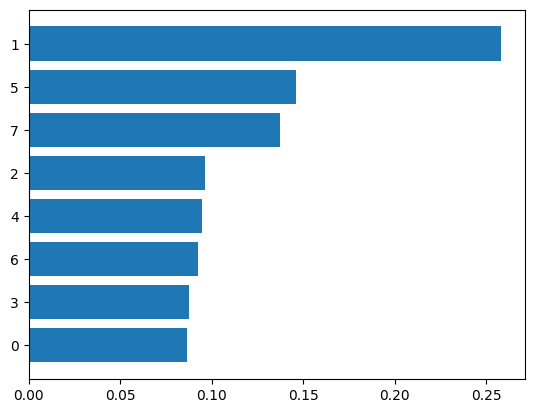

In [53]:
plt.barh(fidf["features"],fidf["importances"])

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

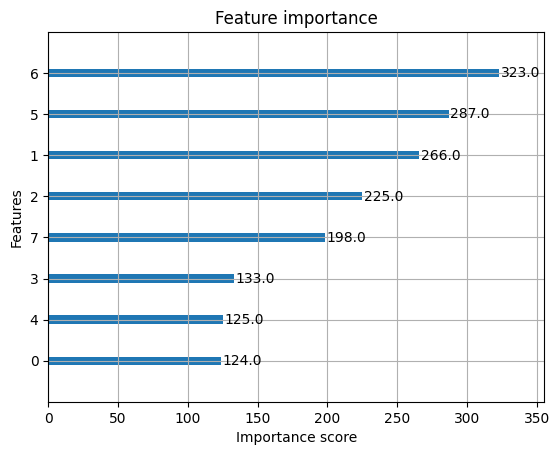

In [54]:
plot_importance(model)

#### Feature selection using XGBOOST Feature importance scores

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=7)
model = XGBClassifier()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print("Accuracy: %.2f%%" % (accuracy * 100.0))


Accuracy: 75.20%


In [56]:
thresholds = np.sort(model.feature_importances_)


    Fit model using each importance as a threshold

In [58]:
for thresh in thresholds:
    selection = SelectFromModel(model, threshold=thresh, prefit=True) #This builds a selector that keeps every feature whose importance is less than the threshold
    select_X_train = selection.transform(X_train.values) #This line makes the selection
    #train with features below the threshold leves
    selection_model = XGBClassifier()
    selection_model.fit(select_X_train,y_train)
    #eval model
    select_X_test = selection.transform(X_test.values)
    predictions = selection_model.predict(select_X_test)
    accuracy = accuracy_score(y_test,predictions)
    print("Thresh=%.3f, n=%d, Accuracy: %.2f%%" % (thresh, select_X_train.shape[1],
accuracy*100.0))


    

Thresh=0.083, n=8, Accuracy: 75.20%
Thresh=0.091, n=7, Accuracy: 71.26%
Thresh=0.093, n=6, Accuracy: 71.65%
Thresh=0.101, n=5, Accuracy: 67.32%
Thresh=0.102, n=4, Accuracy: 69.29%
Thresh=0.135, n=3, Accuracy: 72.83%
Thresh=0.145, n=2, Accuracy: 70.08%
Thresh=0.250, n=1, Accuracy: 68.50%
